# homework 7 - pandas

## 2. pandas dataframe

In [1]:
import pandas as pd

### load the state data

In [2]:
states = pd.read_csv('state_data.csv')
print(states.shape)

(52, 4)


In [3]:
print('first five rows:')
display(states.head())
print('last five rows:')
display(states.tail())
print('columns:', list(states.columns))
print('first state:', states.iloc[0, 0])
print('last state:', states.iloc[-1, 0])
print('total entries:', len(states))

first five rows:


,state,latitude,longitude,name
0,AK,63.588753,-154.493062,Alaska
1,AL,32.318231,-86.902298,Alabama
2,AR,35.201050,-91.831833,Arkansas
3,AZ,34.048928,-111.093731,Arizona
4,CA,36.778261,-119.417932,California


last five rows:


,state,latitude,longitude,name
47,VT,44.558803,-72.577841,Vermont
48,WA,47.751074,-120.740139,Washington
49,WI,43.784440,-88.787868,Wisconsin
50,WV,38.597626,-80.454903,West Virginia
51,WY,43.075968,-107.290284,Wyoming


columns: ['state', 'latitude', 'longitude', 'name']
first state: AK
last state: WY
total entries: 52


the columns give the state name, abbreviation, latitude, and longitude. the dataset includes washington, d.c. and territories, so there are more than 50 entries.

In [4]:
median_lat = states['latitude'].median()
median_lon = states['longitude'].median()
print('median latitude:', median_lat)
print('median longitude:', median_lon)

median latitude: 39.4355155
median longitude: -89.093198


In [5]:
states['latitude_distance'] = (states['latitude'] - median_lat).abs()
states['longitude_distance'] = (states['longitude'] - median_lon).abs()
print(states.shape)

(52, 6)


In [6]:
near_lat = states.loc[states['latitude_distance'].idxmin()]
far_lat = states.loc[states['latitude_distance'].idxmax()]
near_lon = states.loc[states['longitude_distance'].idxmin()]
far_lon = states.loc[states['longitude_distance'].idxmax()]
print(f"closest latitude: {near_lat['state']}, {near_lat['latitude_distance']:.2f}")
print(f"farthest latitude: {far_lat['state']}, {far_lat['latitude_distance']:.2f}")
print(f"closest longitude: {near_lon['state']}, {near_lon['longitude_distance']:.2f}")
print(f"farthest longitude: {far_lon['state']}, {far_lon['longitude_distance']:.2f}")

closest latitude: CO, 0.11
farthest latitude: AK, 24.15
closest longitude: IL, 0.31
farthest longitude: HI, 66.57


### a new pandas function

In [7]:
states.describe()

,latitude,longitude,latitude_distance,longitude_distance
count,52.000000,52.000000,52.000000,52.000000
mean,39.153437,-92.824719,4.815714,14.535330
std,6.967697,19.431647,4.998411,13.280351
min,18.220833,-155.665857,0.114536,0.305330
25%,35.438381,-102.009600,1.564952,6.037732
50%,39.435516,-89.093198,3.890968,11.903743
75%,43.220246,-78.291302,6.133912,17.832342
max,63.588753,-66.590149,24.153237,66.572659


i found `describe()` in the pandas dataframe documentation. it gives a summary of the numbers, like the mean, minimum, and maximum. it is useful for checking data quickly.

https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.describe.html

## 3. seaborn

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

penguins = sns.load_dataset('penguins')
clean_penguins = penguins.dropna(axis=1)
print(clean_penguins.shape)
print(clean_penguins.head())
print(clean_penguins.tail())
print(clean_penguins.columns)

(344, 2)
  species     island
0  Adelie  Torgersen
1  Adelie  Torgersen
2  Adelie  Torgersen
3  Adelie  Torgersen
4  Adelie  Torgersen
    species  island
339  Gentoo  Biscoe
340  Gentoo  Biscoe
341  Gentoo  Biscoe
342  Gentoo  Biscoe
343  Gentoo  Biscoe
Index(['species', 'island'], dtype='str')


the penguins dataset includes `species` (type of penguin), `island` (where it was observed), `bill_length_mm` (bill length), `bill_depth_mm` (bill depth), `flipper_length_mm` (flipper length), `body_mass_g` (body mass), and `sex` (male or female). the missing-value step removes whichever columns have any blank entries, so some of these will not be in the final dataframe.

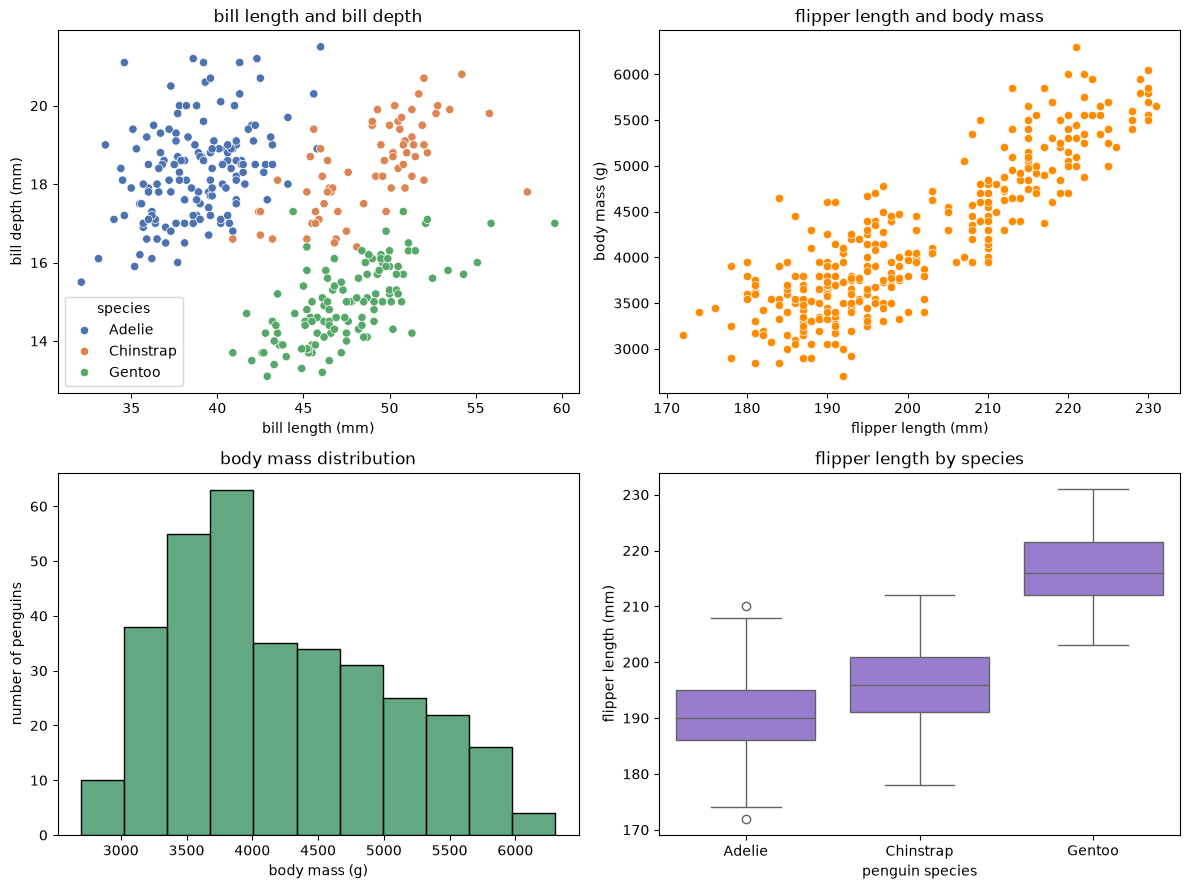

In [9]:
plot_data = penguins.dropna()
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

sns.scatterplot(data=plot_data, x='bill_length_mm', y='bill_depth_mm', hue='species', ax=axes[0, 0], palette='deep')
axes[0, 0].set_title('bill length and bill depth')
axes[0, 0].set_xlabel('bill length (mm)')
axes[0, 0].set_ylabel('bill depth (mm)')

sns.scatterplot(data=plot_data, x='flipper_length_mm', y='body_mass_g', ax=axes[0, 1], color='darkorange')
axes[0, 1].set_title('flipper length and body mass')
axes[0, 1].set_xlabel('flipper length (mm)')
axes[0, 1].set_ylabel('body mass (g)')

sns.histplot(data=plot_data, x='body_mass_g', ax=axes[1, 0], color='seagreen')
axes[1, 0].set_title('body mass distribution')
axes[1, 0].set_xlabel('body mass (g)')
axes[1, 0].set_ylabel('number of penguins')

sns.boxplot(data=plot_data, x='species', y='flipper_length_mm', ax=axes[1, 1], color='mediumpurple')
axes[1, 1].set_title('flipper length by species')
axes[1, 1].set_xlabel('penguin species')
axes[1, 1].set_ylabel('flipper length (mm)')

plt.tight_layout()
plt.show()

the first graph compares bill length and depth. the species seem to have different bill shapes.

the second graph shows that heavier penguins tend to have longer flippers.

the histogram shows the range of body masses.

the boxplot shows that gentoo penguins usually have longer flippers.

i used rows without missing values for the graphs because dropping every column with a missing value removes the measurements needed for the plots.